# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import FindACarParkDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/find_a_car_park/",
    "csv_file": "./data/find_a_car_park/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = FindACarParkDataset(dataset_config)

## Show images from the dataset

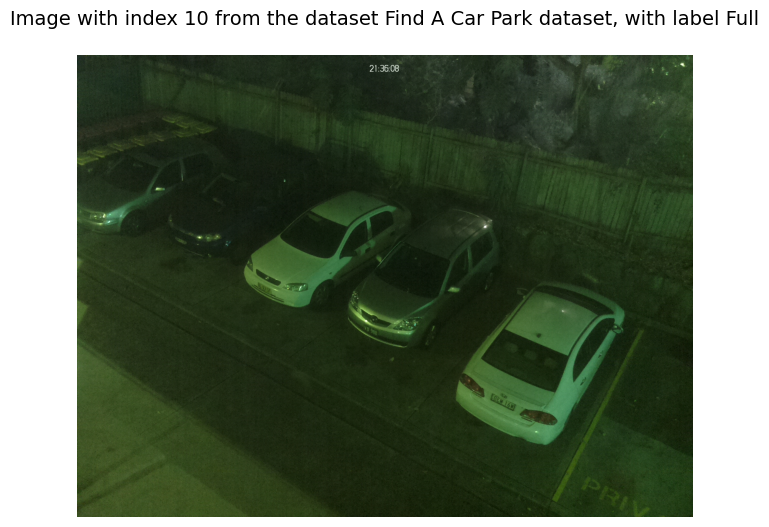

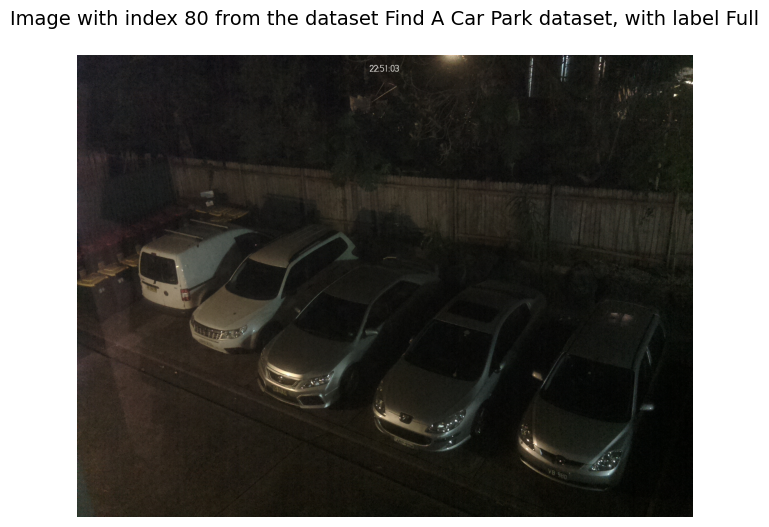

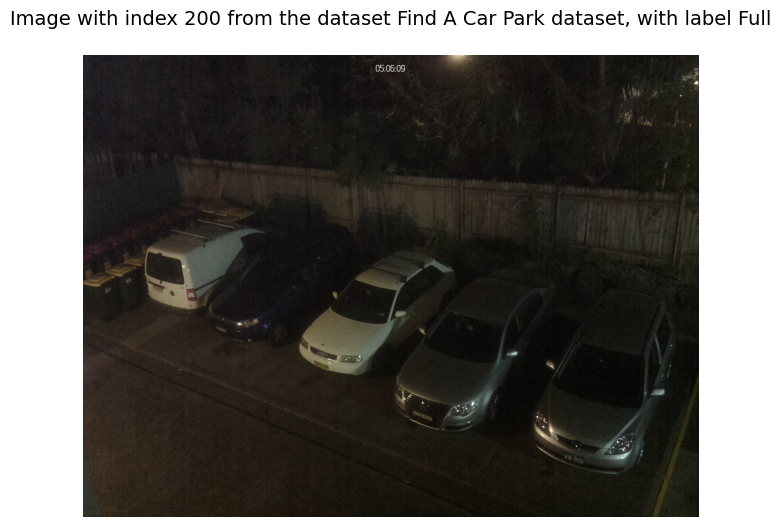

In [7]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

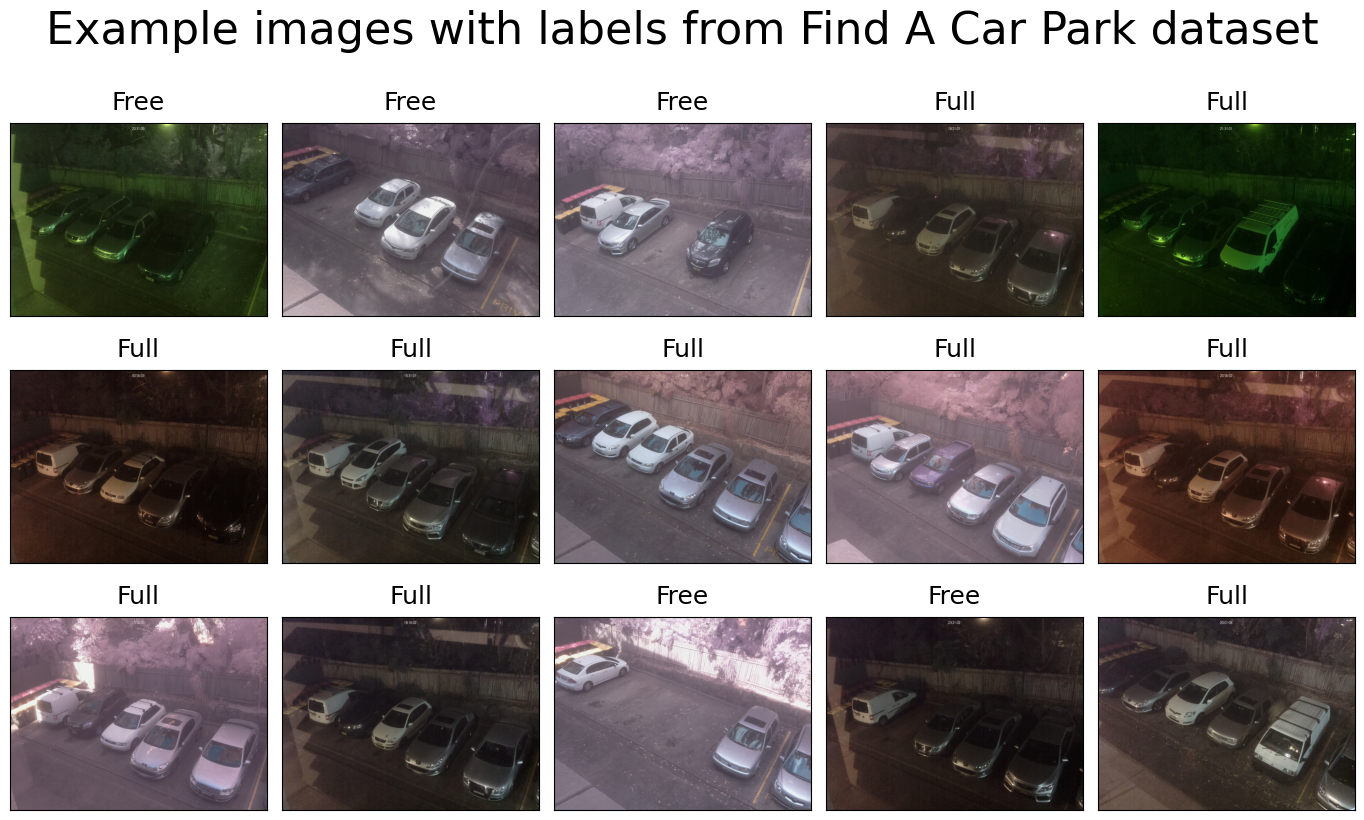

In [8]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [9]:
dataset.show_samples()

,File name,Label
0,Full/img_1002014602.jpg,Full
1,Full/img_909080057.jpg,Full
2,Full/img_902015102.jpg,Full
3,Free/img_912153558.jpg,Free
4,Free/img_1019120058.jpg,Free
5,Full/img_919152558.jpg,Full
6,Full/img_920053602.jpg,Full
7,Full/img_909152058.jpg,Full
8,Free/img_1006104558.jpg,Free
9,Full/img_901181103.jpg,Full


In [10]:
dataset.data_distribution_table()

,Label,Count
0,Free,858
1,Full,1752


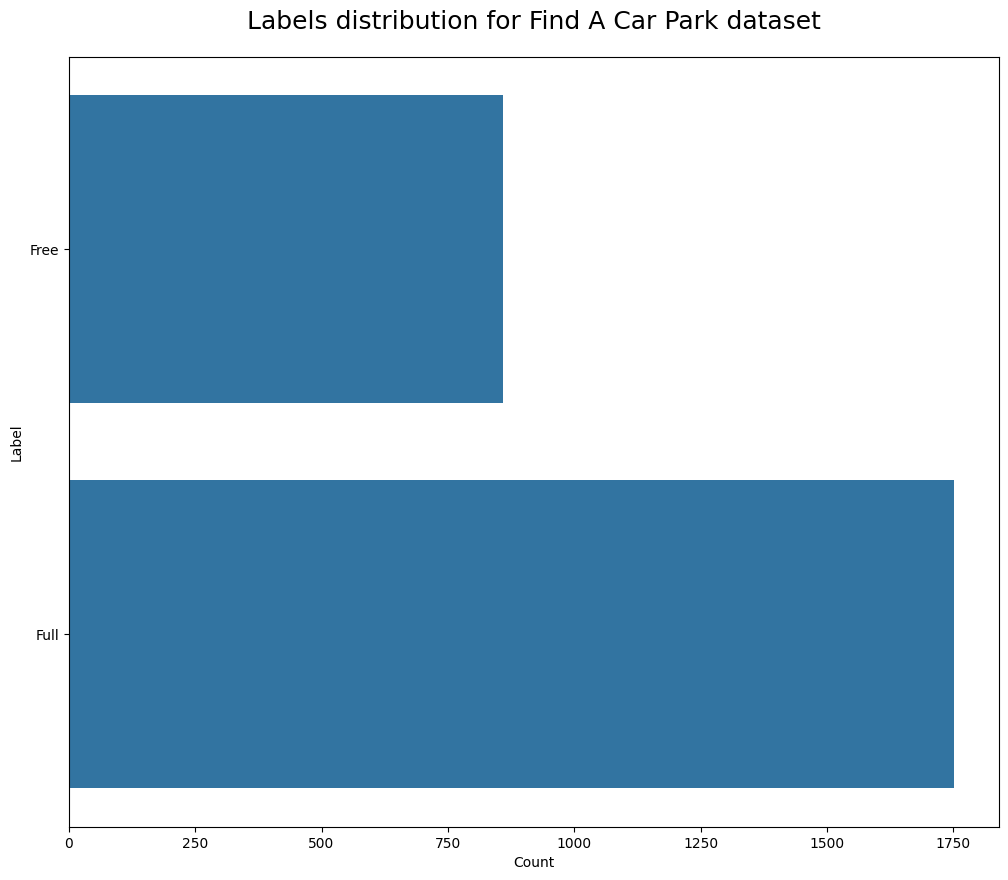

In [11]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/find_a_car_park/",
    "csv_file": "./data/find_a_car_park/train.csv",
}

train_dataset = FindACarParkDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/find_a_car_park/",
    "csv_file": "./data/find_a_car_park/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = FindACarParkDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(2610, 326)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/find_a_car_park/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-15 06:27:49,049 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-15 06:27:49,179 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [15]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-15 06:27:55,721 INFO Starting training.
training: 100%|██████████| 82/82 [00:22<00:00,  3.72it/s]
2025-05-15 06:28:17,873 INFO epoch: 1, time: 22, loss:  0.35905
testing on train set: 100%|██████████| 82/82 [00:13<00:00,  6.01it/s]
2025-05-15 06:28:33,855 INFO Accuracy:0.9509578544061302, Precision Micro:0.9509578544061302, Precision Macro:0.9508641975308643, Precision Weighted:0.9509487725273167, Precision per Class:[0.95061728 0.95111111], Recall Micro:0.9509578544061302, Recall Macro:0.9373024236037935, Recall Weighted:0.9509578544061303, Recall per Class:[0.8974359  0.97716895], F1_score Micro:0.9509578544061297, F1_score Macro:0.9436126774256264, F1_score Weighted:0.9505835778720912, F1_score per Class:[0.92326139 0.96396396]
testing on validation set: 100%|██████████| 11/11 [00:02<00:00,  4.50it/s]
2025-05-15 06:28:36,309 INFO Accuracy:0.9815950920245399, Precision Micro:0.9815950920245399, Precision Macro:0.9811504424778761, Precision Weighted:0.9815809761659156, Precisi

0.07840357141505028

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/find_a_car_park/",
    "csv_file": "./data/find_a_car_park/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = FindACarParkDataset(test_dataset_config)
model_path = "./data/experiments/find_a_car_park/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-15 06:34:23,739 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/find_a_car_park/checkpoint.pth.tar
2025-05-15 06:34:24,113 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/find_a_car_park/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 21/21 [00:02<00:00,  9.40it/s]


[{'Accuracy': 0.9938650306748467},
 {'Precision Micro': 0.9938650306748467,
  'Precision Macro': 0.9908256880733946,
  'Precision Weighted': 0.9939775989193449,
  'Precision per Class': array([0.98165138, 1.        ])},
 {'Recall Micro': 0.9938650306748467,
  'Recall Macro': 0.995433789954338,
  'Recall Weighted': 0.9938650306748467,
  'Recall per Class': array([1.        , 0.99086758])},
 {'F1_score Micro': 0.9938650306748461,
  'F1_score Macro': 0.9930767923887184,
  'F1_score Weighted': 0.9938793622800484,
  'F1_score per Class': array([0.99074074, 0.99541284])}]

## Predictions

2025-05-15 07:19:15,207 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/find_a_car_park/checkpoint.pth.tar
2025-05-15 07:19:16,178 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/find_a_car_park/checkpoint.pth.tar at epoch 11


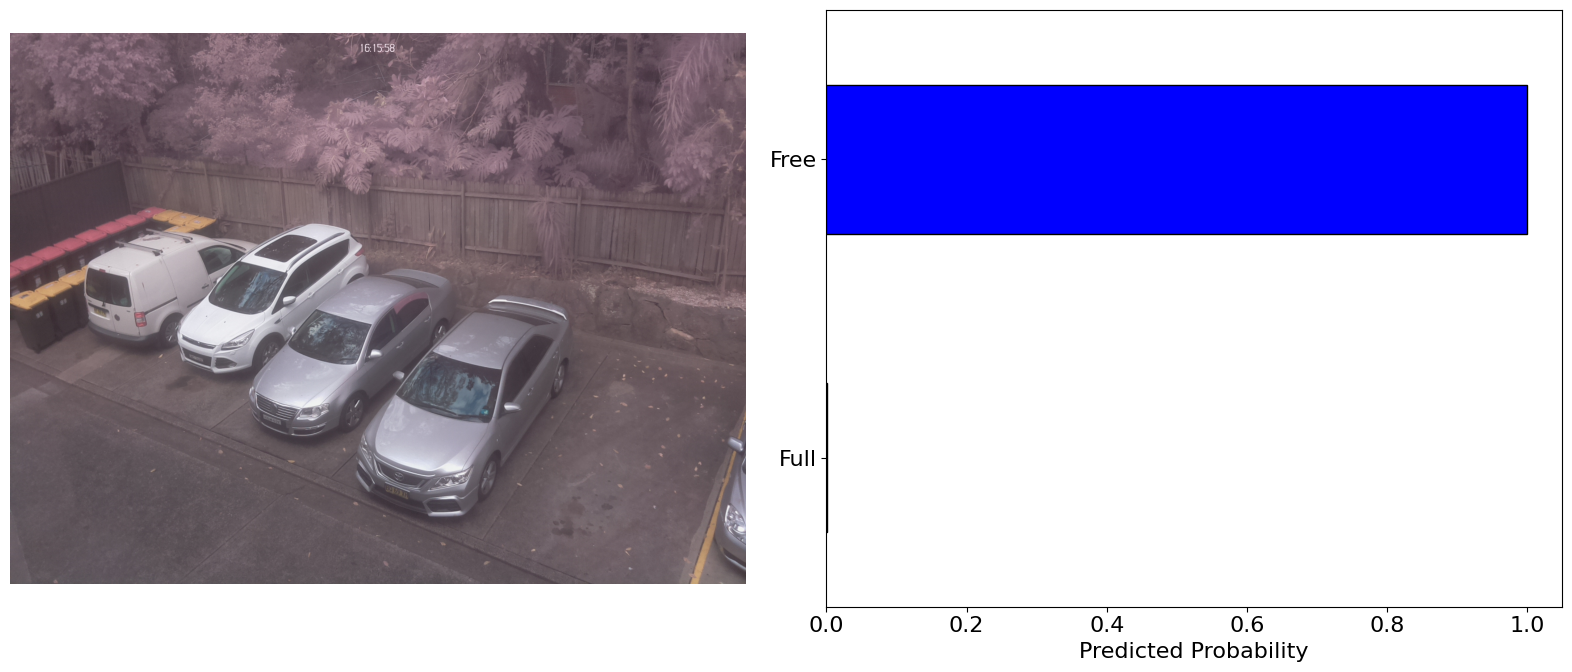

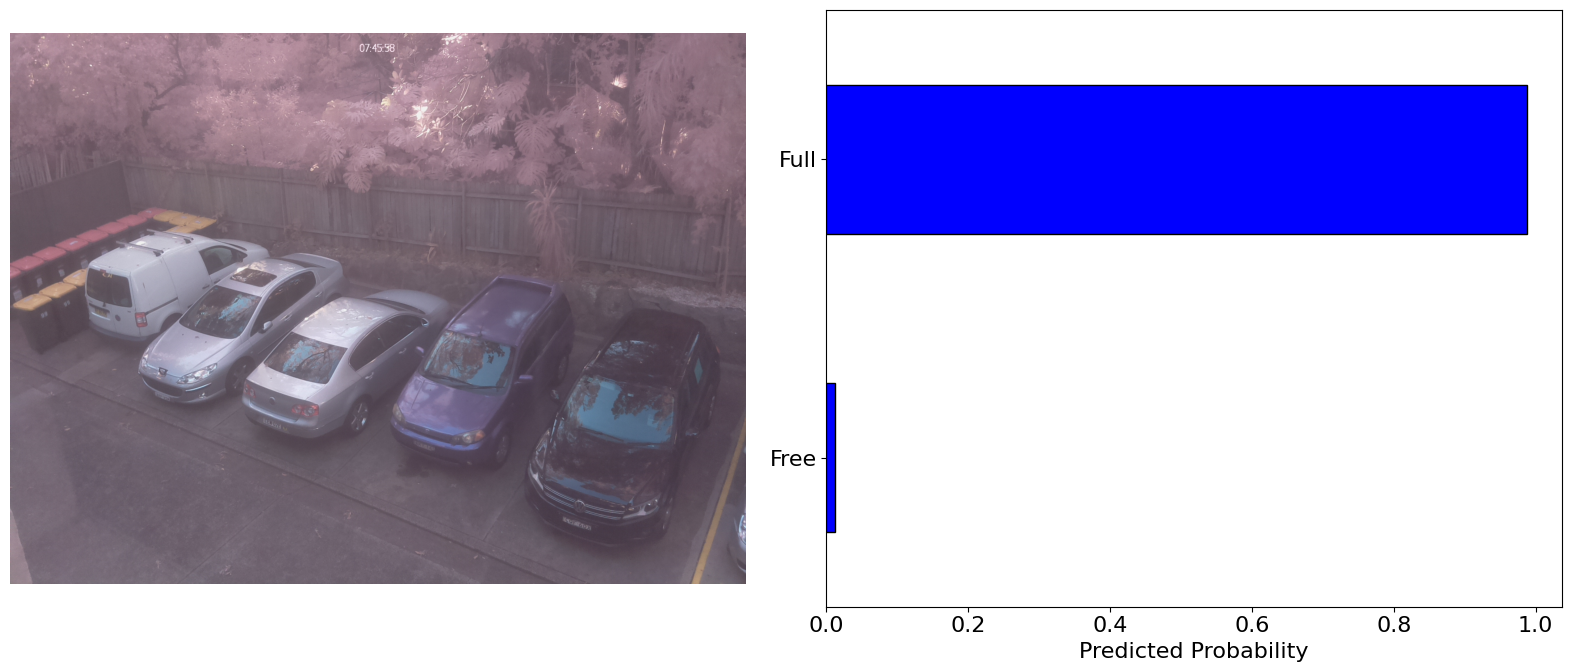

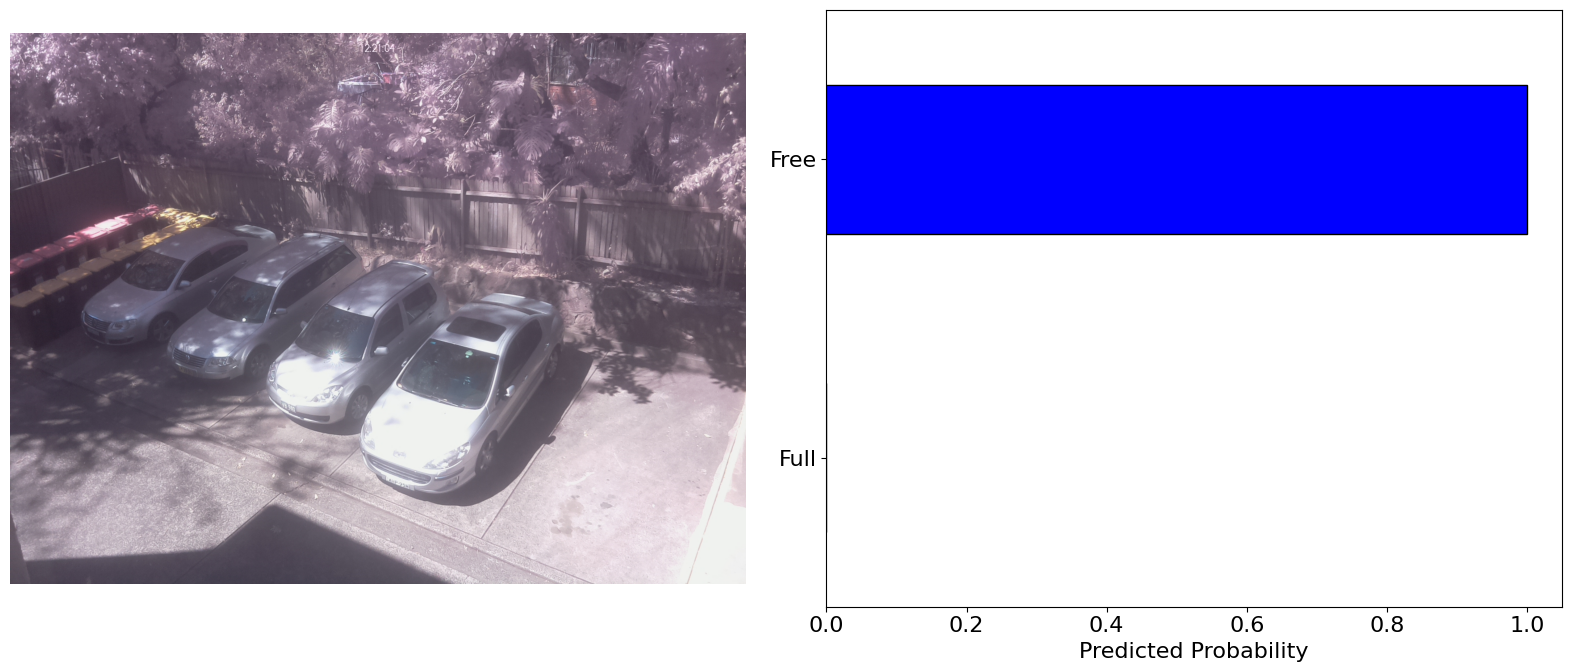

In [ ]:
labels = ["Free","Full"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/find_a_car_park/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/find_a_car_park/Free/img_824161558.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/find_a_car_park/Full/img_816074558.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/find_a_car_park/Free/img_919122058.jpg')
fig = model.predict_image(image, labels, transform)